In [37]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import classification_report, accuracy_score
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt

In [14]:
# Cargar el archivo
file_path = 'DataEarlyPrediction_Train - Sheet1.csv'
df = pd.read_csv(file_path, decimal=',')



In [15]:
# Muestra las primeras 5 filas para verificar la lectura
print(df.head())

   Nota Laboratorio Uno  Tiempo Entrega Laboratorio Uno  \
0                   1.7                            0.25   
1                   4.9                            0.65   
2                   0.5                           13.71   
3                   3.1                            0.48   
4                   0.0                            0.38   

   Total Intentos Laboratorio Uno  Nota Laboratorio Dos  \
0                               1                   1.1   
1                               2                   4.8   
2                              13                   5.0   
3                               1                   0.8   
4                               1                   4.6   

   Nota Laboratorio Tres  Clase  
0                    3.4      0  
1                    4.8      2  
2                    5.0      1  
3                    4.8      0  
4                    5.0      0  


In [16]:
# 2. Separar variables de entrada (X) y variable objetivo (y)
X = df.drop(columns=['Clase'])
y = df['Clase']

In [17]:
# 3. Dividir los datos en entrenamiento (80%) y prueba (20%)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [18]:
# 4. Crear e instanciar el modelo del Árbol de Decisión
# Usamos max_depth=3 para evitar el sobreajuste (overfitting)
modelo = DecisionTreeClassifier(max_depth=3, random_state=42)

In [19]:
# 5. Entrenar el modelo
modelo.fit(X_train, y_train)

DecisionTreeClassifier(max_depth=3, random_state=42)

In [20]:
# 6. Realizar predicciones sobre el conjunto de prueba
y_pred = modelo.predict(X_test)

In [21]:
# 7. Evaluar el rendimiento
print("Precisión (Accuracy):", accuracy_score(y_test, y_pred))
print("\nReporte de Clasificación:\n", classification_report(y_test, y_pred))

Precisión (Accuracy): 0.8533333333333334

Reporte de Clasificación:
               precision    recall  f1-score   support

           0       0.78      0.97      0.86        29
           1       0.96      0.71      0.81        34
           2       0.86      1.00      0.92        12

    accuracy                           0.85        75
   macro avg       0.86      0.89      0.87        75
weighted avg       0.87      0.85      0.85        75



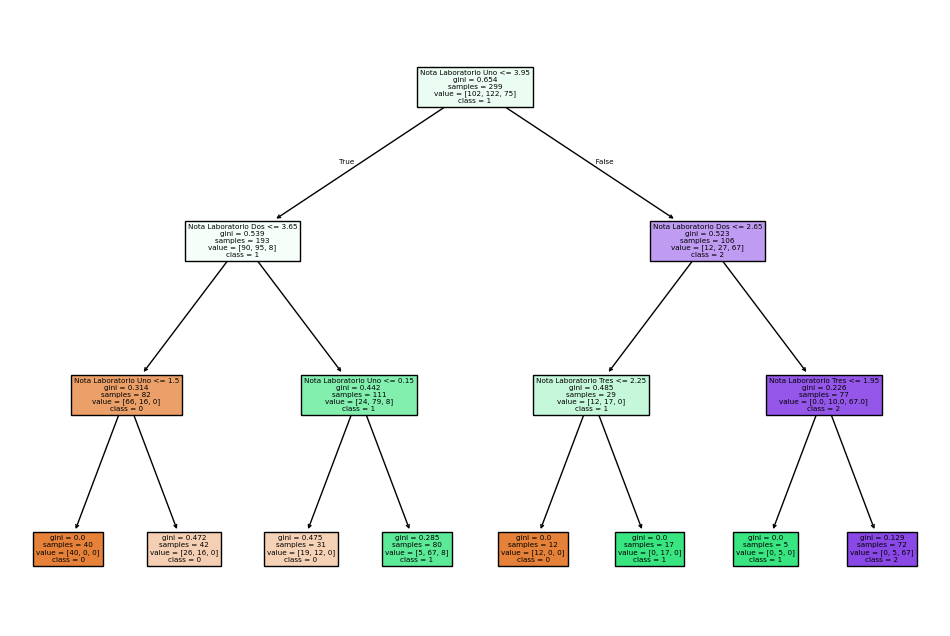

In [22]:
# 8. Visualizar el árbol de decisión
plt.figure(figsize=(12, 8))
plot_tree(
    modelo,
    feature_names=X.columns,
    class_names=[str(c) for c in modelo.classes_],
    filled=True
)
plt.show()

Evaluacion del modelo con el archivo de test

In [31]:
# Cargar el archivo
file_path_test = 'DataEarlyPrediction_Test - Hoja 1.csv'
df_test_nuevo = pd.read_csv(file_path_test, decimal=',')

In [32]:
# Muestra las primeras 5 filas para verificar la lectura
print(df_test_nuevo.head())

  Nota Laboratorio Uno Tiempo Entrega Laboratorio Uno  \
0                  3.9                            0.5   
1                    0                           0.53   
2                  4.8                           0.48   
3                  4.7                           0.33   
4                    1                           1.52   

   Total Intentos Laboratorio Uno Nota Laboratorio Dos Nota Laboratorio Tres  \
0                               1                  4.9                     5   
1                               5                    5                     5   
2                               1                    5                     5   
3                               1                  3.8                   3.8   
4                               6                    0                   4.1   

   Clase  
0      1  
1      0  
2      2  
3      2  
4      0  


In [33]:
# 2. Asegurar que todas las características sean numéricas
X_test_nuevo = df_test_nuevo.drop(columns=['Clase']).copy()
for col in X_test_nuevo.columns:
    X_test_nuevo[col] = X_test_nuevo[col].astype(str).str.replace(',', '.')
    X_test_nuevo[col] = pd.to_numeric(X_test_nuevo[col], errors='coerce')

y_test_nuevo = df_test_nuevo['Clase']

In [34]:
# 3. Generar las predicciones con el modelo ya entrenado
y_pred_nuevo = modelo.predict(X_test_nuevo)

In [35]:
# 4. Mostrar las predicciones junto a las clases reales
df_resultados = df_test_nuevo.copy()
df_resultados['Clase_Predicha'] = y_pred_nuevo
print("--- Primeras filas con las predicciones del modelo ---")
print(df_resultados[['Clase', 'Clase_Predicha']].head())

--- Primeras filas con las predicciones del modelo ---
   Clase  Clase_Predicha
0      1               1
1      0               0
2      2               2
3      2               2
4      0               0


In [38]:
# 5. Evaluar las métricas de rendimiento del clasificador
print("\n--- Resultados de la Evaluación ---")
print("Precisión global (Accuracy):", accuracy_score(y_test_nuevo, y_pred_nuevo))
print("\nMatriz de Confusión:\n", confusion_matrix(y_test_nuevo, y_pred_nuevo))
print("\nReporte de Clasificación Detallado:\n", classification_report(y_test_nuevo, y_pred_nuevo))


--- Resultados de la Evaluación ---
Precisión global (Accuracy): 0.8085106382978723

Matriz de Confusión:
 [[28  3  0]
 [14 30  0]
 [ 0  1 18]]

Reporte de Clasificación Detallado:
               precision    recall  f1-score   support

           0       0.67      0.90      0.77        31
           1       0.88      0.68      0.77        44
           2       1.00      0.95      0.97        19

    accuracy                           0.81        94
   macro avg       0.85      0.84      0.84        94
weighted avg       0.84      0.81      0.81        94

